# 半满蜂窝晶格：Green 函数与实空间物理量

使用 `test/test.jl` 的 `HoneyComb120`、周期边界和半满 Slater 态；Julia 导出 Green 矩阵，Python 计算物理量并绘图。
默认 **12 × 12 原胞、288 个格点、144 个无自旋费米子（或单个自旋分量）**。
这里的 $S_x,S_y,S_z$ 按你的要求表示 **A/B 子晶格赝自旋**。

图包括格点粒子数、原胞粒子数与赝自旋、局域涨落、参考原胞的连通关联、DW 关联、键能和键电流。
原胞图用斜平行四边形，黑圈标记参考原胞，和给出的示例采用相同的表达方式。
图形使用真实 HoneyComb120 基矢，最近邻距离为单位长度。每张图同时保存 PNG 和 PDF，数值保存 CSV/NPZ。

**先看这个区别：** 单点期望值均匀并不意味着连通关联为零。`Initial_Pt!("H0")` 内部还加了交错势
$m(-n_A+n_B)$，$m=10^{-5}$，因此默认结果并非严格 $m=0$ 时唯一确定的基态。
本 notebook 同时保留无质量零模的对称高斯混合态，最后一节比较两者。

## 1. 参数与运行

依赖：Julia 使用仓库的 `Project.toml`；Python ≥ 3.11，包见本目录 `requirements.txt`。
首次可在仓库根目录运行：
```powershell
python -m pip install -r test/Free_WaveFunction/requirements.txt
julia --project=. test/Free_WaveFunction/export_green.jl 12 12
```
然后执行本 notebook 的所有单元格。缺少数据时下面也会自动调用 Julia。
修改 `LX, LY` 可改变尺寸，`REFERENCE_XY` 是 **Julia 风格、从 1 开始** 的参考原胞坐标。
`STATE="reference"` 精确采用 `test.jl` 的选态，`STATE="symmetric"` 切换到零模对称高斯混合态。

In [1]:
from pathlib import Path
import sys
import subprocess
try:
    import tomllib
except ModuleNotFoundError:
    import tomli as tomllib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.collections import LineCollection
from IPython.display import display, Markdown

LX, LY = 12, 12
STATE = "reference"                 # "reference" or "symmetric"
REFERENCE_XY = (LX // 2 + 1, LY // 2 + 1)
REGENERATE = False                  # True: rerun the Julia exporter
CORRELATION_SCALE = "symlog"        # "linear" or "symlog"
CORRELATION_LINTHRESH = 1e-5         # linear window around zero

# Works when the kernel starts at the repository root or in this notebook folder.
roots = [p for p in (Path.cwd(), *Path.cwd().parents)
         if (p / "src" / "KAPDQMC.jl").is_file()]
if not roots:
    raise FileNotFoundError("Start the notebook kernel inside the KAPDQMC repository.")
ROOT = roots[0]
HERE = ROOT / "test" / "Free_WaveFunction"
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from wavef_observables import (
    OPERATORS, real_checked, connected, cell_observables,
    reference_correlations, density_connected, lattice_geometry,
    signed_norm, cell_map, site_map, visible_bonds, decorate_axis, save_figure,
)
DATA_DIR = HERE / "data" / f"L{LX}x{LY}"
RUN_NAME = f"{STATE}_ref{REFERENCE_XY[0]}_{REFERENCE_XY[1]}"
FIG_DIR = HERE / "figures" / f"L{LX}x{LY}" / RUN_NAME
RESULT_DIR = HERE / "results" / f"L{LX}x{LY}" / RUN_NAME
if STATE not in {"reference", "symmetric"}:
    raise ValueError("STATE must be reference or symmetric")
if REGENERATE or not (DATA_DIR / "metadata.toml").exists():
    result = subprocess.run(
        ["julia", f"--project={ROOT}", str(HERE / "export_green.jl"), str(LX), str(LY)],
        cwd=ROOT, check=True, capture_output=True, text=True,
    )
    print(result.stdout)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 12, "axes.labelsize": 11, "axes.grid": False,
    "savefig.facecolor": "white", "figure.facecolor": "white",
})

## 2. Green 函数和物理量约定

为避免粒子/空穴、转置以及 $S_y$ 符号混淆，统一记
$$P_{ij}=[P_t(P_t^\dagger P_t)^{-1}P_t^\dagger]_{ij}
=\langle c_j^\dagger c_i\rangle.$$
它就是 `test.jl` 中名为 `G` 的矩阵。若使用 DQMC 的空穴约定，则
$$G^{\rm hole}_{ij}=\langle c_i c_j^\dagger\rangle=\delta_{ij}-P_{ij},\qquad
C_{ij}=\langle c_i^\dagger c_j\rangle=P_{ji}.$$

每个原胞取 $\psi_R=(c_{R,A},c_{R,B})^T$，$S_R^\alpha=\frac12\psi_R^\dagger\sigma_\alpha\psi_R$。

| 量 | 本 notebook 的公式 |
|---|---|
| 格点粒子数 | $n_i=P_{ii}$ |
| 原胞粒子数 | $N_R=n_{R,A}+n_{R,B}$ |
| $S_R^z$ | $(n_{R,A}-n_{R,B})/2$ |
| $S_R^x$ | $\operatorname{Re}P_{R,A;R,B}$ |
| $S_R^y$ | $-\operatorname{Im}P_{R,A;R,B}$ |
| DW（本文定义） | $D_R=n_{R,A}-n_{R,B}=2S_R^z$ |

DW 在此仅指原胞 A/B 密度差；未假定示例图片中的 DW 使用同一归一化。
因此 $\langle D_RD_0\rangle_c=4\langle S_R^zS_0^z\rangle_c$。
赝自旋允许空原胞和双占据原胞，不是每个原胞被强制限制为一个自旋 $1/2$。
$S_x$ 是原胞内相干性/键序，$S_y$ 对应其虚部，它们依赖 A/B 轨道相位约定。

In [2]:
with (DATA_DIR / "metadata.toml").open("rb") as handle:
    meta = tomllib.load(handle)
assert (meta["Lx"], meta["Ly"]) == (LX, LY)
def load_green(stem):
    return (np.loadtxt(DATA_DIR / f"{stem}_real.csv", delimiter=",")
            + 1j * np.loadtxt(DATA_DIR / f"{stem}_imag.csv", delimiter=","))
P_reference = load_green("G_occupied")
P_symmetric = load_green("G_symmetric")
P = P_reference if STATE == "reference" else P_symmetric
K = np.loadtxt(DATA_DIR / "K.csv", delimiter=",")
G_hole = np.eye(meta["Ns"]) - P
geometry = lattice_geometry(meta, REFERENCE_XY)
ref_cell = geometry["reference_cell"]
ref_A = 2 * ref_cell
n = real_checked(np.diag(P))
means, variances = cell_observables(P)
correlations = reference_correlations(P, ref_cell)
nn_connected = density_connected(P)
spectrum = np.genfromtxt(DATA_DIR / "spectrum.csv", delimiter=",", names=True)

display(Markdown(
    f"当前选态：**{STATE}**；{LX} × {LY} 原胞，{meta['Ns']} 格点，"
    f"$\\langle N_{{tot}}\\rangle$ = {n.sum():.12g}。参考原胞：**{REFERENCE_XY}**。  \n"
    f"A/B 平均密度：**{n[0::2].mean():.9f} / {n[1::2].mean():.9f}**；"
    f"无质量零能模数：**{meta['zero_mode_count']}**。"
))

当前选态：**reference**；12 × 12 原胞，288 格点，$\langle N_{tot}\rangle$ = 144。参考原胞：**(7, 7)**。  
A/B 平均密度：**0.506948365 / 0.493051635**；无质量零能模数：**4**。

### 连通关联与自关联项

对 $O_R=\psi_R^\dagger A\psi_R$、$Q_{R'}=\psi_{R'}^\dagger B\psi_{R'}$，Wick 定理给出
$$\langle O_RQ_{R'}\rangle_c=
\operatorname{Tr}\big[A(\delta_{RR'}I-P_{RR'})B P_{R'R}\big].$$
格点密度的特例为 $\langle n_i n_j\rangle_c=\delta_{ij}n_i-|P_{ij}|^2$。
同点必须保留 $\delta$ 项，例如 $\mathrm{Var}(n_i)=n_i(1-n_i)$；把同点也写成 $-|P_{ii}|^2$ 会得到错误符号。
相关图为 **固定参考位置的原始连通关联，未除以参考点方差，也未做空间平均**。

这里沿用粒子数守恒高斯态的 Wick 收缩；密度关联的推导可参考
[ETH 课程讲义，第 3.1.6 节](https://people.phys.ethz.ch/~ivanov/cmt/1314/ssth-lecture5.pdf)。
本项目函数 `wavef_observables.connected` 使用上面的指标约定；另有小系统 Fock 空间精确计算核对复数态与 $S_y$ 的符号。
数值在 $10^{-14}$ 附近的残差（例如略负的总粒子数方差）属于浮点舍入误差。

In [3]:
# Numerical and physical checks: a finite lattice has no statistical error bars here.
eigenvalues = np.linalg.eigvalsh(P)
assert P.shape == (meta["Ns"], meta["Ns"])
assert np.allclose(P, P.conj().T, atol=1e-11)
assert eigenvalues.min() > -1e-10 and eigenvalues.max() < 1 + 1e-10
assert abs(n.sum() - meta["Np"]) < 1e-9
assert np.max(np.abs(P + G_hole - np.eye(len(P)))) < 1e-12
geometry_K = np.zeros_like(K)
bond_i, bond_j = geometry["bond_pairs"].T
geometry_K[bond_i, bond_j] = geometry_K[bond_j, bond_i] = 1.0
assert np.allclose(K, geometry_K, atol=1e-12)  # plotted bonds match Julia's Hamiltonian
assert np.allclose(means["Sy"], -P[0::2, 1::2].diagonal().imag)
assert np.allclose(np.diag(nn_connected), n * (1 - n), atol=1e-11)
assert np.allclose(correlations["DW"], 4 * correlations["Sz"], atol=1e-11)
for name in OPERATORS:
    assert variances[name].min() > -1e-10
    assert abs(correlations[name][ref_cell] - variances[name][ref_cell]) < 1e-10
if STATE == "reference":
    assert np.linalg.norm(P @ P - P) < 1e-9
    assert np.max(np.abs(nn_connected.sum(axis=0))) < 1e-9  # fixed total N
else:
    assert np.max(np.abs(n - 0.5)) < 1e-10
    assert abs(nn_connected.sum() - meta["zero_mode_count"] / 4) < 1e-9
print(f"Hermiticity error: {np.linalg.norm(P - P.conj().T):.2e}")
print(f"Projector error ||P²-P||: {np.linalg.norm(P @ P - P):.2e}")
print(f"Total-number variance: {nn_connected.sum():.6g}")
print("All Green-function, Wick, normalization and particle-number checks passed.")

Hermiticity error: 4.72e-15
Projector error ||P²-P||: 8.71e-15
Total-number variance: -4.20844e-15
All Green-function, Wick, normalization and particle-number checks passed.


## 3. 每个格点的粒子数

左图显示绝对占据数，右图显示相对半满的偏差。圆点 A、三角形 B。
灰线仅画当前展开区域内的最近邻键；跨边界连线不画出，但计算始终包含所有周期边界键。
色标不自动放大浮点舍入噪声：绝对密度使用 $[0,1]$，偏差图的范围至少为 $\pm0.01$。

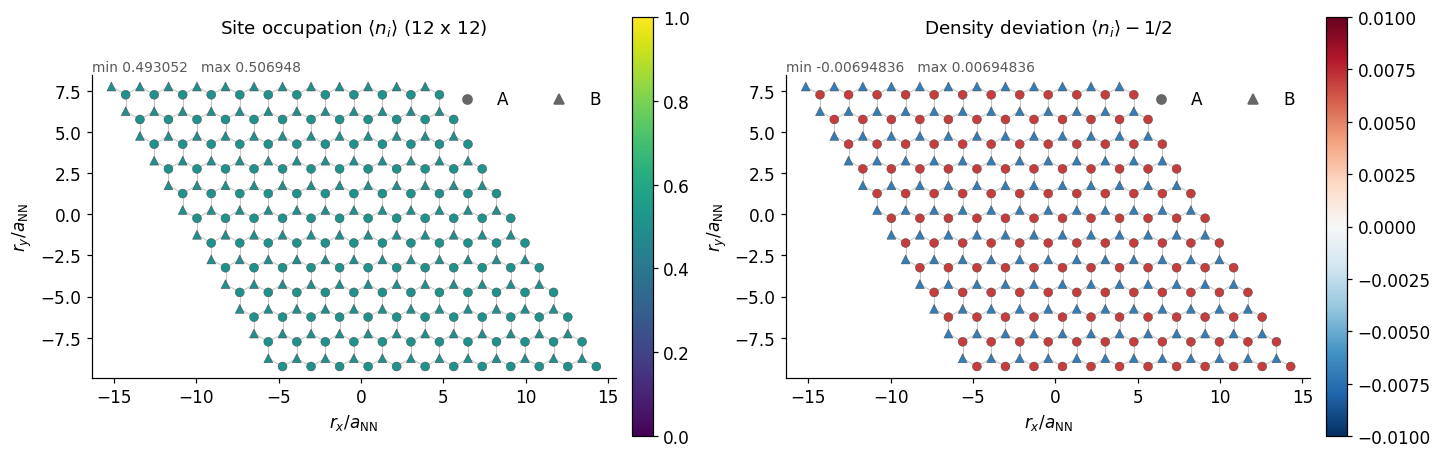

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
site_map(axes[0], n, geometry, rf"Site occupation $\langle n_i\rangle$ ({LX} x {LY})",
         norm=Normalize(0, 1), cmap="viridis")
site_map(axes[1], n - 0.5, geometry, r"Density deviation $\langle n_i\rangle-1/2$",
         norm=signed_norm(n - 0.5, limit=max(0.01, np.max(np.abs(n - 0.5)))))
save_figure(fig, FIG_DIR, "01_site_density")
plt.show()

## 4. 每个原胞的 $N,S_x,S_y,S_z$

每块斜平行四边形表示一个原胞。采用原始 120° 基矢
$\mathbf a_1=(\sqrt3,0)$、$\mathbf a_2=(-\sqrt3/2,3/2)$，
$\boldsymbol\delta_{AB}=(-\sqrt3/2,1/2)$；与 `nn2idx` 的三种最近邻对应。
相对坐标在各基矢方向做周期折回，这是一个基本平行四边形，**不是欧氏最短距离折回**。
三个赝自旋图统一使用 $[-1/2,1/2]$ 色标；很小的 $S_z$ 请同时看数值范围。

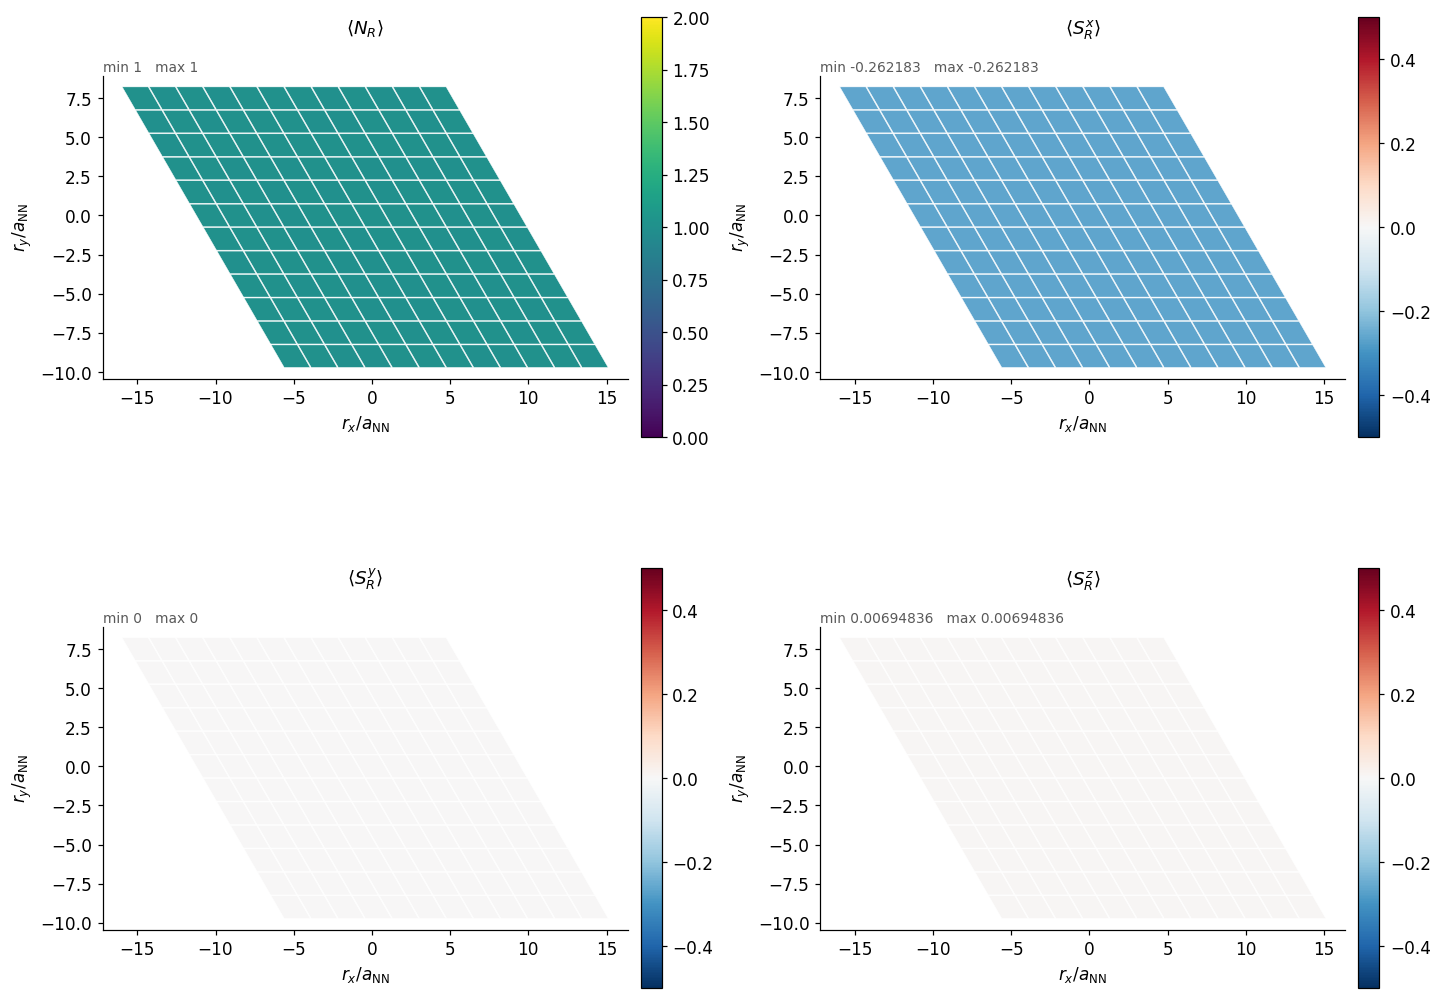

| Observable | Mean | Spatial max − min |
|---|---:|---:|
| N | 1 | 1.55e-15 |
| Sx | -0.262182553 | 2.64e-14 |
| Sy | 0 | 0 |
| Sz | 0.00694836473 | 5.83e-16 |
| DW | 0.0138967295 | 1.17e-15 |

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")
for ax, name, label in zip(axes.flat, ("N", "Sx", "Sy", "Sz"),
                         (r"$\langle N_R\rangle$", r"$\langle S_R^x\rangle$",
                          r"$\langle S_R^y\rangle$", r"$\langle S_R^z\rangle$")):
    cell_map(ax, means[name], geometry, label,
             norm=Normalize(0, 2) if name == "N" else signed_norm(means[name], limit=0.5),
             cmap="viridis" if name == "N" else "RdBu_r")
save_figure(fig, FIG_DIR, "02_cell_means")
plt.show()
rows = ["| Observable | Mean | Spatial max − min |", "|---|---:|---:|"]
rows += [f"| {name} | {means[name].mean():.9g} | {np.ptp(means[name]):.3g} |"
         for name in ("N", "Sx", "Sy", "Sz", "DW")]
display(Markdown("\n".join(rows)))

## 5. 局域涨落

均值为零的量也可以有非零量子涨落。下面计算每个原胞的
$\mathrm{Var}(O_R)=\langle O_R^2\rangle-\langle O_R\rangle^2$。
为便于直接比较，四个图使用同一色标；与“原胞之间的均值方差”不同，这里是各个位置的算符涨落。

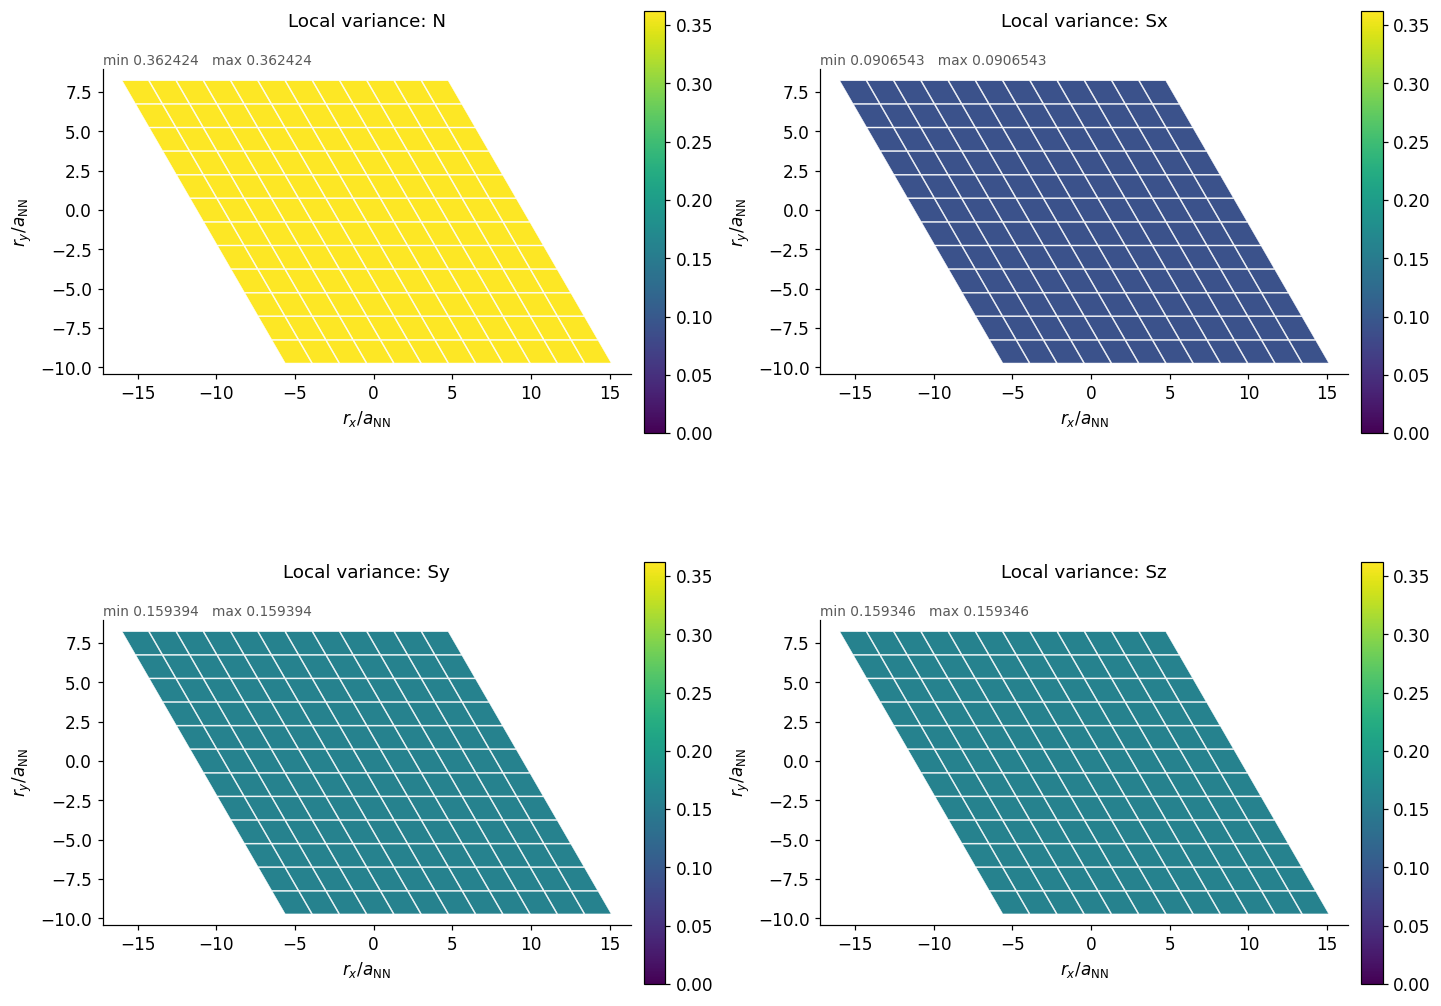

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")
variance_limit = max(0.25, max(variances[name].max() for name in ("N", "Sx", "Sy", "Sz")))
for ax, name in zip(axes.flat, ("N", "Sx", "Sy", "Sz")):
    cell_map(ax, variances[name], geometry, f"Local variance: {name}",
             norm=Normalize(0, variance_limit), cmap="viridis")
save_figure(fig, FIG_DIR, "03_local_fluctuations")
plt.show()

## 6. 与参考原胞的连通关联

黑圈位于 $R=0$。默认使用关于零点对称的 **symlog 色标**：
在 $|C|\le10^{-5}$ 内线性，在外部按对数压缩，保留符号并使远距离关联可见。
可以在参数区改成 `CORRELATION_SCALE="linear"`。四个面板使用各自的数值范围，不能仅凭颜色比较不同量的大小。

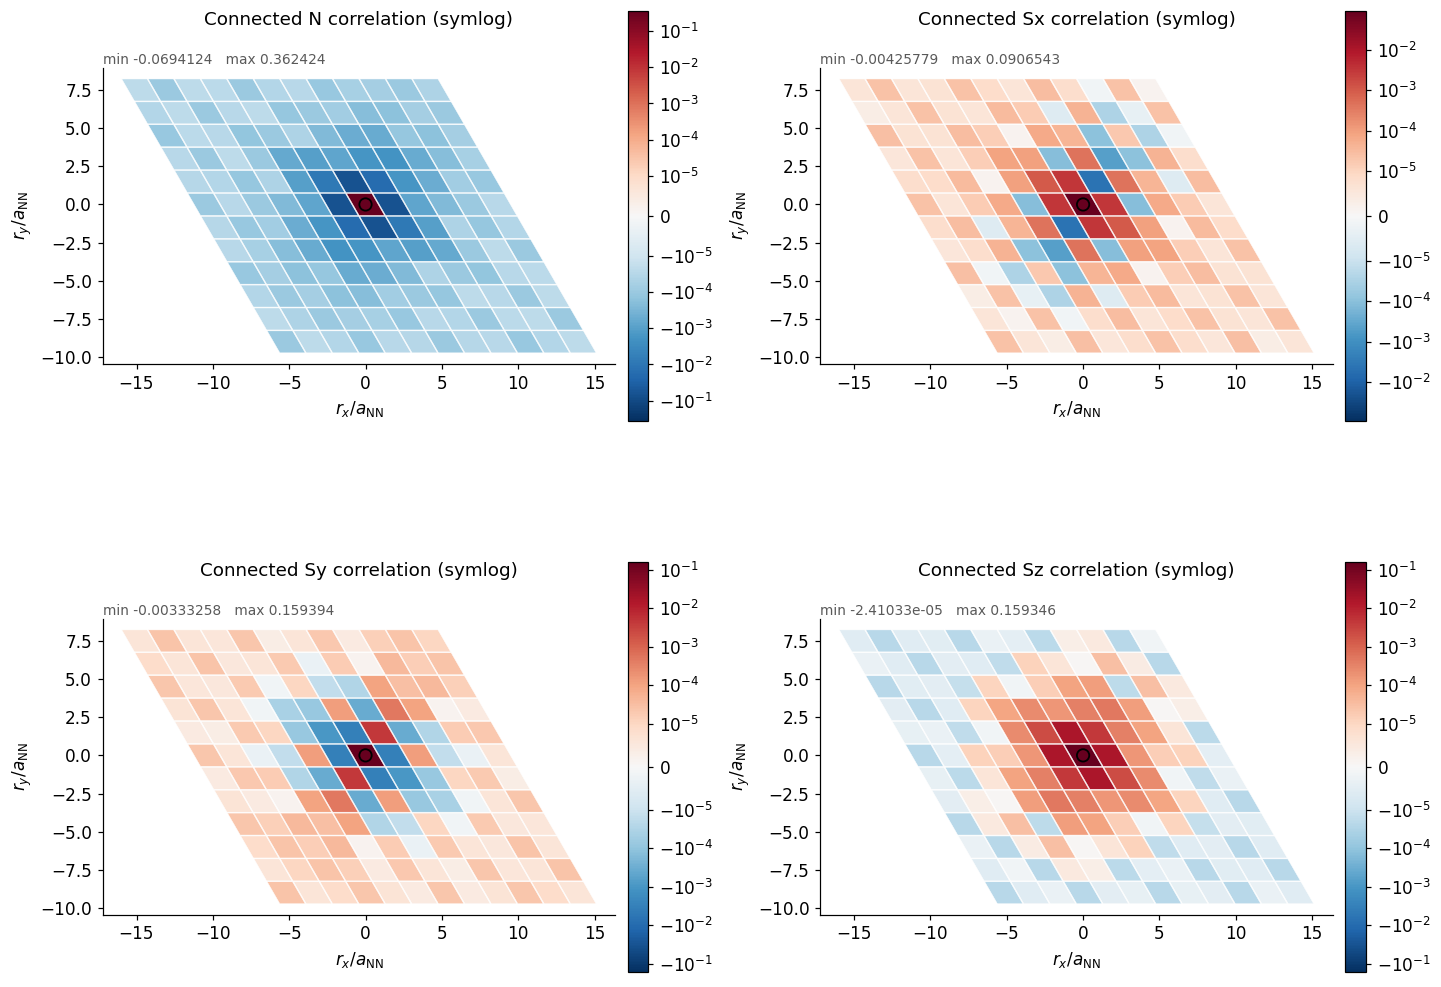

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")
for ax, name in zip(axes.flat, ("N", "Sx", "Sy", "Sz")):
    values = correlations[name]
    cell_map(ax, values, geometry, f"Connected {name} correlation ({CORRELATION_SCALE})",
             norm=signed_norm(values, mode=CORRELATION_SCALE, linthresh=CORRELATION_LINTHRESH),
             reference=True)
save_figure(fig, FIG_DIR, "04_cell_connected_correlations")
plt.show()

### DW 图：完整线性色标和去除原点后的细节

定义 $D_R=n_{R,A}-n_{R,B}$，图为 $\langle D_RD_0\rangle_c$。
左图保留原点及对称线性色标；右图仅在绘图时屏蔽原点，并用 symlog 放大非局域结构。
右图原点灰块表示屏蔽，不代表零值；导出的数值始终包含原点。
这个展示方式避免把正负两侧使用不同线性缩放误认为同一幅度，也避免自关联把远处信号完全压住。

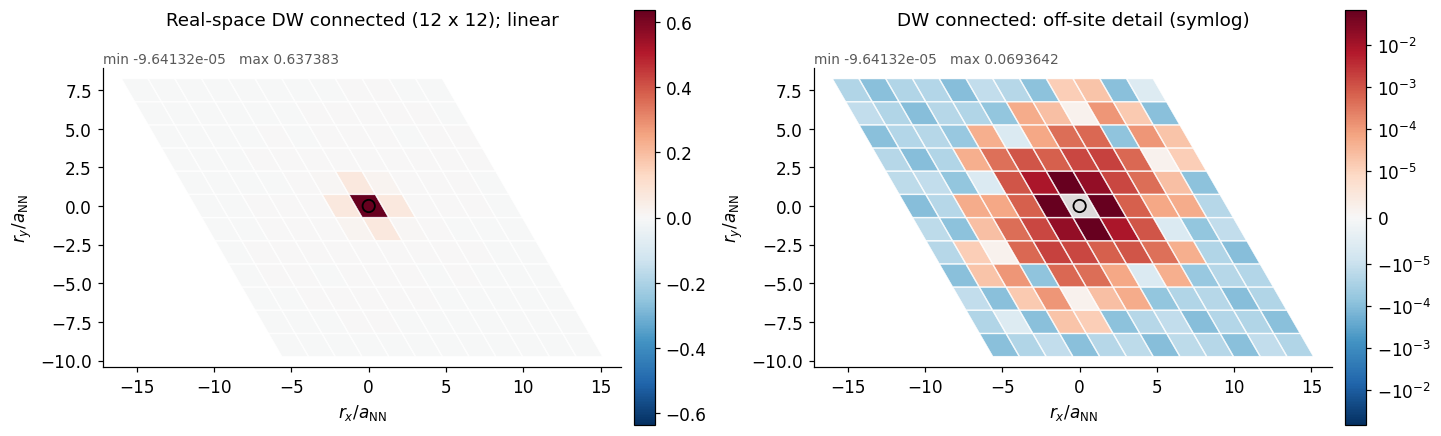

DW self-correlation: 0.637382822
DW off-site range: [-9.64132224e-05, 0.0693641816]


In [8]:
dw = correlations["DW"]
offsite = np.arange(len(dw)) != ref_cell
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
cell_map(axes[0], dw, geometry, f"Real-space DW connected ({LX} x {LY}); linear",
         norm=signed_norm(dw), reference=True)
cell_map(axes[1], dw, geometry, "DW connected: off-site detail (symlog)",
         norm=signed_norm(dw[offsite], mode="symlog", linthresh=CORRELATION_LINTHRESH),
         reference=True, mask_reference=True)
save_figure(fig, FIG_DIR, "05_DW_connected")
plt.show()
print(f"DW self-correlation: {dw[ref_cell]:.9g}")
print(f"DW off-site range: [{dw[offsite].min():.9g}, {dw[offsite].max():.9g}]")

### 格点分辨的密度关联

下面固定参考原胞的 A 格点，画 $\langle n_i n_{0,A}\rangle_c$。
对不同格点，结果应为非正的 $-|P_{i,0A}|^2$；参考格点本身为正的占据数涨落。

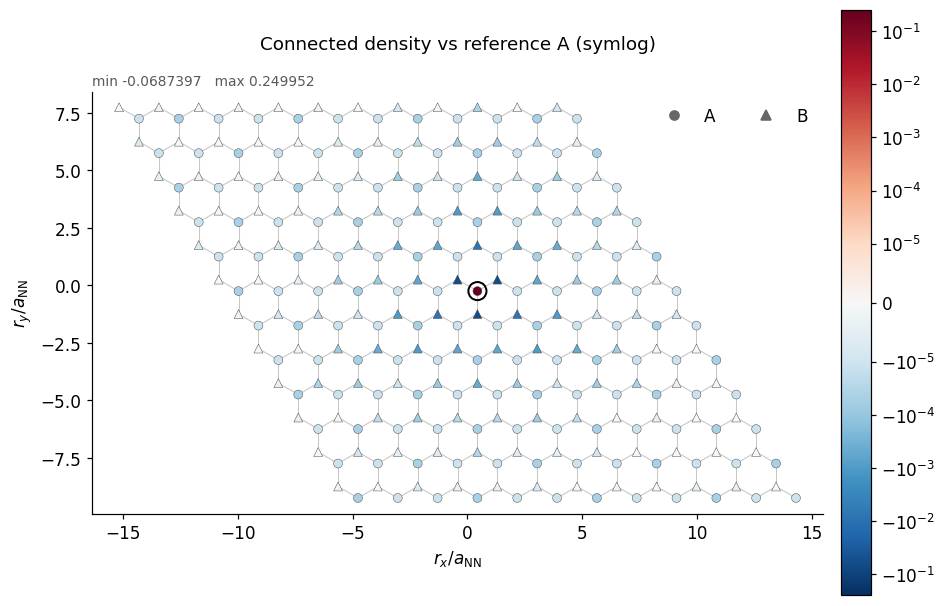

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 6.3), layout="constrained")
values = nn_connected[:, ref_A]
site_map(ax, values, geometry, f"Connected density vs reference A ({CORRELATION_SCALE})",
         norm=signed_norm(values, mode=CORRELATION_SCALE, linthresh=CORRELATION_LINTHRESH),
         reference_site=ref_A)
save_figure(fig, FIG_DIR, "06_site_density_connected")
plt.show()

## 7. 最近邻键能与电流

保持 `test.jl` 的正号 hopping 约定 $H_0=\sum_{ij}c_i^\dagger K_{ij}c_j$。
每条无向 A–B 键只计一次：
$$E_{ij}=2\operatorname{Re}(K_{ij}P_{ji}),\qquad
J_{i\to j}=-2\operatorname{Im}(K_{ij}P_{ji}),\quad \dot n_i=-\sum_jJ_{i\to j}.$$
若改用 $H=-t\sum(c_i^\dagger c_j+\mathrm{h.c.})$，应同步改变哈密顿量，不能只翻转显示符号。
当前实 hopping、实选态没有电流。右图色标保留有限范围，避免把数值零放大。

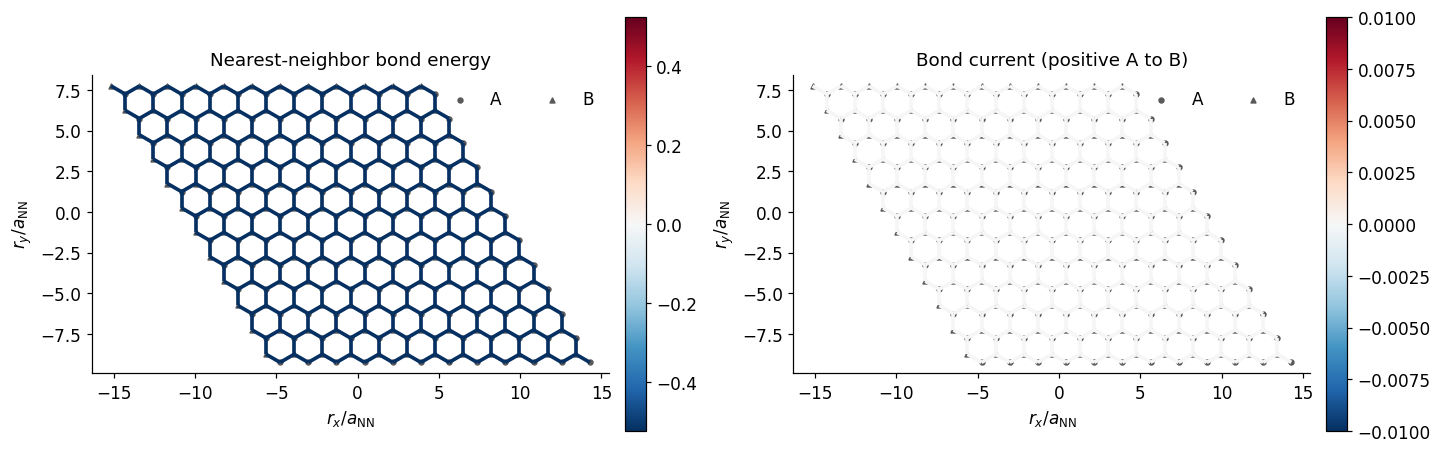

Kinetic energy / cell = -1.57309532
Max |bond current| = 0


In [10]:
bond_pairs = geometry["bond_pairs"]
ii, jj = bond_pairs.T
bond_amplitudes = K[ii, jj] * P[jj, ii]
bond_energy = 2 * bond_amplitudes.real
bond_current = -2 * bond_amplitudes.imag
assert len(bond_pairs) == 3 * LX * LY
assert np.allclose(np.sum(bond_energy), np.trace(K @ P).real, atol=1e-9)
segments, visible = visible_bonds(geometry)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
for ax, values, title, norm in (
    (axes[0], bond_energy, "Nearest-neighbor bond energy", signed_norm(bond_energy)),
    (axes[1], bond_current, "Bond current (positive A to B)",
     signed_norm(bond_current, limit=max(0.01, np.max(np.abs(bond_current))))),
):
    lines = LineCollection(segments, array=values[visible], cmap="RdBu_r", norm=norm, linewidths=2.4)
    ax.add_collection(lines)
    ax.scatter(*geometry["positions"][0::2].T, s=10, color="0.35", marker="o", label="A")
    ax.scatter(*geometry["positions"][1::2].T, s=10, color="0.35", marker="^", label="B")
    ax.autoscale_view()
    ax.set_title(title)
    ax.legend(frameon=False, ncol=2)
    decorate_axis(ax)
    fig.colorbar(lines, ax=ax, fraction=0.04, pad=0.025)
save_figure(fig, FIG_DIR, "07_bond_energy_current")
plt.show()
print(f"Kinetic energy / cell = {bond_energy.sum() / (LX * LY):.9g}")
print(f"Max |bond current| = {np.max(np.abs(bond_current)):.3g}")

## 8. 有限尺寸零模与选态对照

默认的 `reference` 态完全重现 `Initial_Pt!("H0")`：填充
$K+10^{-5}\operatorname{diag}(-1,+1,\ldots)$ 的最低一半能级。
当晶格包含 Dirac 零模时，小交错势会选定其子晶格占据；有限尺寸密度偏差不一定与 $10^{-5}$ 同阶。
这不是相互作用自发有序的证据。

`symmetric` 是严格无交错势 $K$ 的高斯态：负能模填满、正能模空置，**每个零能模独立以 1/2 概率占据**。
它保持 A/B 对称，平均粒子数为半满，但有零模时是粒子数可涨落的混合态，
不是固定粒子数的纯 Slater 态，也不等价于固定粒子数下等权平均所有简并态。
因此它满足 Wick 定理，但 $P^2\ne P$，$\mathrm{Var}(N_{tot})=N_{zero}/4$。
没有零模的尺寸则不需要这一步混合。

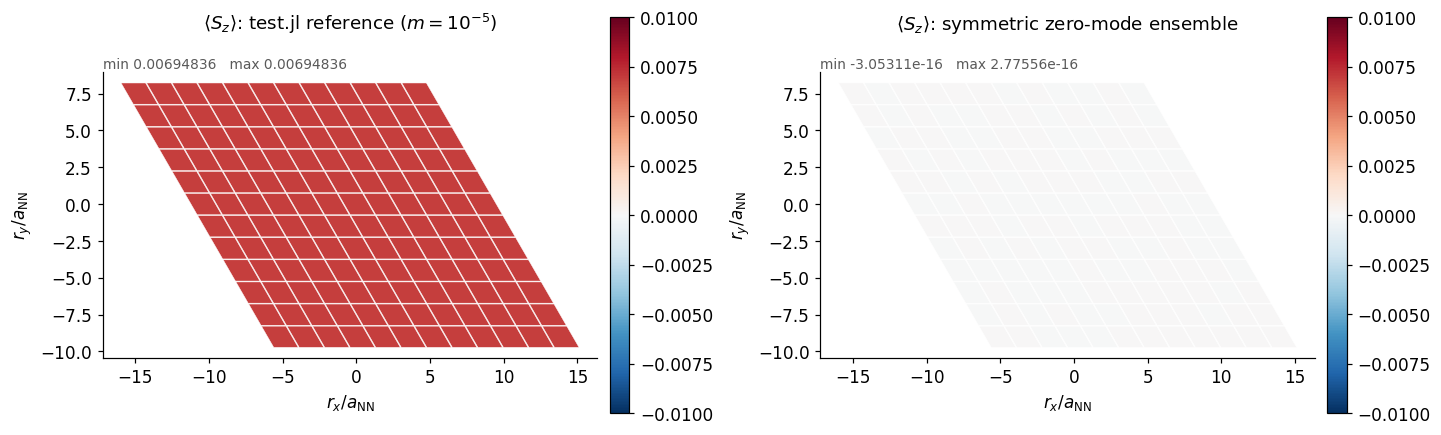

| State | mean nA | mean nB | mean Sz | Var(N total) |
|---|---:|---:|---:|---:|
| reference | 0.506948365 | 0.493051635 | 0.00694836473 | -4.20843915e-15 |
| symmetric | 0.500000000 | 0.500000000 | -1.15648232e-18 | 1 |

In [11]:
mean_ref, _ = cell_observables(P_reference)
mean_sym, _ = cell_observables(P_symmetric)
comparison_limit = max(0.01, np.max(np.abs(mean_ref["Sz"])), np.max(np.abs(mean_sym["Sz"])))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
for ax, values, title in (
    (axes[0], mean_ref["Sz"], r"$\langle S_z\rangle$: test.jl reference ($m=10^{-5}$)"),
    (axes[1], mean_sym["Sz"], r"$\langle S_z\rangle$: symmetric zero-mode ensemble"),
):
    cell_map(ax, values, geometry, title, norm=signed_norm(values, limit=comparison_limit))
save_figure(fig, FIG_DIR, "08_zero_mode_comparison")
plt.show()
comparison = ["| State | mean nA | mean nB | mean Sz | Var(N total) |",
              "|---|---:|---:|---:|---:|"]
for label, matrix, obs in (("reference", P_reference, mean_ref), ("symmetric", P_symmetric, mean_sym)):
    density = matrix.diagonal().real
    comparison.append(f"| {label} | {density[0::2].mean():.9f} | {density[1::2].mean():.9f} "
                      f"| {obs['Sz'].mean():.9g} | {density_connected(matrix).sum():.9g} |")
display(Markdown("\n".join(comparison)))

## 9. 导出与结果摘要

保存完整精度数据，不屏蔽同点关联。所有 CSV 的 `site,cell,x,y` 均从 1 开始，
而 `dx,dy` 是相对参考原胞的整数位移。`site_observables.csv` 中的关联是相对于参考 A 格点；
`cell_observables.csv` 中的关联是相对于参考原胞。NPZ 同时包含粒子和空穴 Green 函数。

In [12]:
cell_xy = geometry["cell_xy"] + 1
cell_ids = np.arange(1, LX * LY + 1)
site_ids = np.arange(1, meta["Ns"] + 1)
site_table = np.column_stack([
    site_ids, np.repeat(cell_ids, 2), np.repeat(cell_xy, 2, axis=0),
    np.tile([0, 1], LX * LY), geometry["positions"], n, n - 0.5, n * (1 - n),
    nn_connected[:, ref_A],
])
np.savetxt(RESULT_DIR / "site_observables.csv", site_table, delimiter=",", comments="",
           header="site,cell,x,y,sublattice_0A_1B,rx,ry,n,dn_half,var_n,connected_n_refA")
names = ("N", "Sx", "Sy", "Sz", "DW")
cell_table = np.column_stack([
    cell_ids, cell_xy, geometry["displacements"], geometry["centers"],
    *[means[name] for name in names], *[variances[name] for name in names],
    *[correlations[name] for name in names],
])
cell_header = ("cell,x,y,dx,dy,rx,ry," + ",".join(names) + ","
               + ",".join(f"var_{name}" for name in names) + ","
               + ",".join(f"connected_{name}" for name in names))
np.savetxt(RESULT_DIR / "cell_observables.csv", cell_table, delimiter=",", comments="", header=cell_header)
np.savetxt(RESULT_DIR / "bond_observables.csv",
           np.column_stack([ii + 1, jj + 1, np.tile([1, 2, 3], LX * LY), bond_energy, bond_current]),
           delimiter=",", comments="", header="site_A,site_B,direction_1_2_3,energy,current_A_to_B")
np.savez_compressed(
    RESULT_DIR / "observables.npz", P=P, G_hole=G_hole, K=K, n=n,
    density_connected=nn_connected, state=STATE, reference_xy=REFERENCE_XY,
    convention="P[i,j]=<c_j^dagger c_i>; G_hole=I-P",
    **{f"mean_{k}": v for k, v in means.items()},
    **{f"var_{k}": v for k, v in variances.items()},
    **{f"connected_{k}": v for k, v in correlations.items()},
)
# Keep the input conventions beside exported results.
(RESULT_DIR / "source_metadata.toml").write_bytes((DATA_DIR / "metadata.toml").read_bytes())
summary = (
    f"当前 {STATE} 态：每个原胞平均粒子数 {means['N'].mean():.9g}；"
    f"平均 (Sx, Sy, Sz) = ({means['Sx'].mean():.9g}, {means['Sy'].mean():.9g}, {means['Sz'].mean():.9g})。  \n"
    f"DW 连通自关联 {dw[ref_cell]:.9g}，非局域范围 [{dw[offsite].min():.9g}, {dw[offsite].max():.9g}]。  \n"
    f"格点占据、赝自旋均值、量子涨落、连通关联、键能/电流以及选态对照已全部计算并保存。  \n\n"
    f"图：`{FIG_DIR.relative_to(ROOT)}`  \n数值：`{RESULT_DIR.relative_to(ROOT)}`"
)
display(Markdown(summary))

当前 reference 态：每个原胞平均粒子数 1；平均 (Sx, Sy, Sz) = (-0.262182553, 0, 0.00694836473)。  
DW 连通自关联 0.637382822，非局域范围 [-9.64132224e-05, 0.0693641816]。  
格点占据、赝自旋均值、量子涨落、连通关联、键能/电流以及选态对照已全部计算并保存。  

图：`test\Free_WaveFunction\figures\L12x12\reference_ref7_7`  
数值：`test\Free_WaveFunction\results\L12x12\reference_ref7_7`